In [28]:

import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../postprocessing").resolve()))
from conversion_gpx import convert_gpx_to_csv

### Chargement des données

In [15]:
gpx_file = Path("Acquisition_4_48.gpx")
csv_gpx_output = Path("Acquisition_4_48.csv")

convert_gpx_to_csv(gpx_file, csv_gpx_output)

donnees_imu_gnss = pd.read_csv("synced_imu_gnss.csv")
donnees_strava = pd.read_csv(csv_gpx_output)

print("Données IMU/GNSS chargées :", donnees_imu_gnss.shape)
print("Données Strava chargées :", donnees_strava.shape)


Conversion terminée ! Fichier enregistré : Acquisition_4_48.csv
Données IMU/GNSS chargées : (537, 9)
Données Strava chargées : (522, 3)


### Aperçu des données

In [36]:
print("\n Les données IMU/GNSS ")
print(donnees_imu_gnss.head())


 Les données IMU/GNSS 
      timestamp   accel_x   accel_y   accel_z   gyro_x   gyro_y  gyro_z  \
0  1.778078e+09  0.915061  0.089121  0.111325  22.9950 -13.8600  8.6450   
1  1.778078e+09  1.012722  0.122732 -0.021533   1.4700   2.5900  2.1175   
2  1.778078e+09  1.119350 -0.010431  0.083692  -4.7775  11.9525 -2.8000   
3  1.778078e+09  0.907131 -0.082289  0.005856  26.4425   6.4225 -8.8200   
4  1.778078e+09  1.212924  0.069174  0.172142   6.5625  13.3000  4.0250   

     latitude  longitude  
0  177.384557   1.068485  
1   49.384563   1.068484  
2   49.384573   1.068478  
3   49.384584   1.068464  
4   49.384587   1.068439  


In [37]:
print("\n Les données Strava ")
print(donnees_strava.head())


 Les données Strava 
                     UTC   Latitude  Longitude
0  2026/05/06 - 14:39:05  49.384609   1.068483
1  2026/05/06 - 14:39:06  49.384622   1.068442
2  2026/05/06 - 14:39:07  49.384632   1.068414
3  2026/05/06 - 14:39:08  49.384642   1.068369
4  2026/05/06 - 14:39:09  49.384636   1.068416


### Nettoyage

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

imu = donnees_imu_gnss.copy()
strava = donnees_strava.copy()

imu = imu.rename(columns={
    "latitude": "Latitude",
    "longitude": "Longitude"
})

# On enlève les coordonnées impossibles
imu = imu[
    imu["Latitude"].between(-90, 90) &
    imu["Longitude"].between(-180, 180)
].copy()

# On garde les points IMU proches de la trajectoire Strava en definissant une marge
marge = 0.001

lat_min = strava["Latitude"].min() - marge
lat_max = strava["Latitude"].max() + marge
lon_min = strava["Longitude"].min() - marge
lon_max = strava["Longitude"].max() + marge

imu = imu[
    imu["Latitude"].between(lat_min, lat_max) &
    imu["Longitude"].between(lon_min, lon_max)
].copy()

print("Points IMU/GNSS gardés :", len(imu))
print("Points Strava gardés   :", len(strava))

Points IMU/GNSS gardés : 524
Points Strava gardés   : 522


### Comparaison des trajectoires

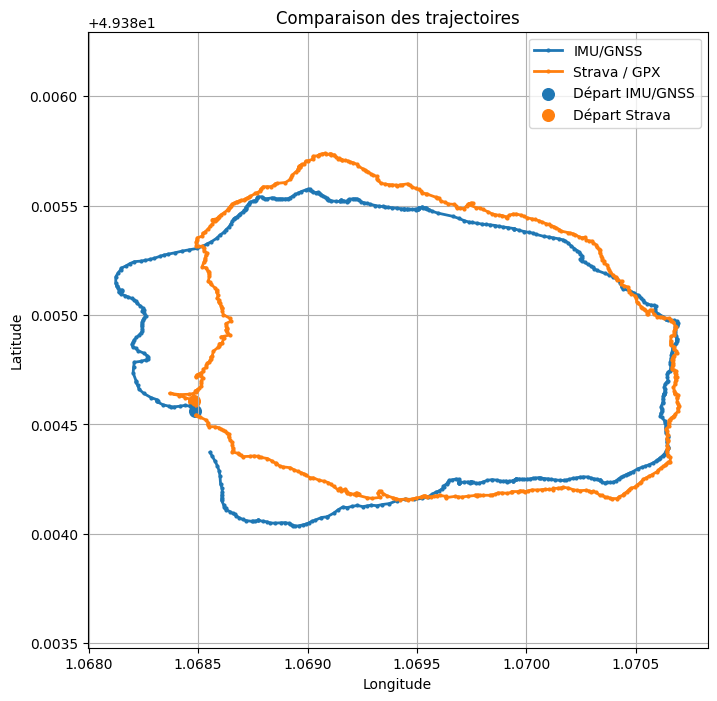

In [33]:

plt.figure(figsize=(8, 8))

plt.plot(
    imu["Longitude"],
    imu["Latitude"],
    label="IMU/GNSS",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.plot(
    strava["Longitude"],
    strava["Latitude"],
    label="Strava / GPX",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.scatter(imu["Longitude"].iloc[0], imu["Latitude"].iloc[0], s=70, label="Départ IMU/GNSS")
plt.scatter(strava["Longitude"].iloc[0], strava["Latitude"].iloc[0], s=70, label="Départ Strava")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Comparaison des trajectoires")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()